# Generate images

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler


#%% Loading the data
df = pd.read_csv("dataset.csv")

# Control NaN values
df = df.drop(columns = ['src_ip', 'Label'], axis = 1)
df.replace([np.inf, -np.inf], np.nan, inplace=True)  # Replace infinity with NaN
df.fillna(df.max(), inplace=True)
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)


In [2]:
import os
import numpy as np
from scipy.stats import pearsonr

# Check if the file exists
if os.path.exists('vfp/sorted_indices_vfp.txt'):
    # Read the sorted indices from the file
    with open('vfp/sorted_indices_vfp.txt', 'r') as file:
        sorted_indices_desc = np.array([int(line.strip()) for line in file.readlines()])
else:
    # Step 1 & 2: Calculate PCCs and sum them for each attribute
    pcc_sums = np.array([sum([pearsonr(df[col], df[other_col])[0] for other_col in df.columns if other_col != col]) for col in df.columns])

    # Step 3: Sort attributes by PCC sums
    sorted_indices_asc = np.argsort(pcc_sums)
    sorted_indices_desc = sorted_indices_asc[::-1]  # Assuming combined_features_sorted is this

    # Ensure the directory exists
    os.makedirs('vfp', exist_ok=True)
    # Write the sorted indices to the file
    with open('vfp/sorted_indices_vfp.txt', 'w') as file:
        for index in sorted_indices_desc:
            file.write(f"{index}\n")

In [3]:
import numpy as np

def arrange_in_vortex(row, indices, image_size):
    # Create an empty matrix for the single-channel image
    image = np.zeros((image_size, image_size))
    # Adjusting for a counterclockwise spiral starting from the center
    center = image_size // 2
    x, y = center, center
    dx, dy = 0, -1  # Adjust initial direction for counterclockwise spiral
    step_size = 1
    steps_count = 0
    change_direction_steps = 1
    direction_changes = 0  # Track the number of direction changes

    for i in range(len(indices)):
        # Check if the current position is within bounds
        if 0 <= x < image_size and 0 <= y < image_size:
            # Access the row by column index
            image[x, y] = row.iloc[indices[i]] * 255
        steps_count += 1
        if steps_count == change_direction_steps:
            steps_count = 0
            direction_changes += 1
            # Change direction
            dx, dy = -dy, dx
            # Increase step size after every two direction changes
            if direction_changes % 2 == 0:
                change_direction_steps += 1

        x, y = x + dx, y + dy

    return image


Index: 0


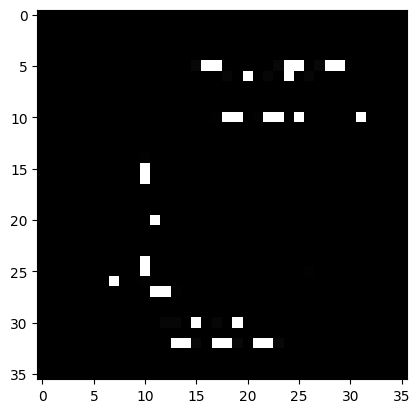

Index: 100


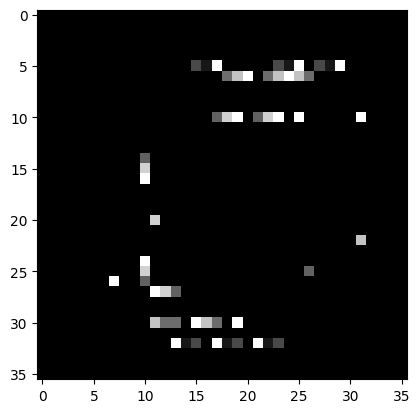

Index: 200


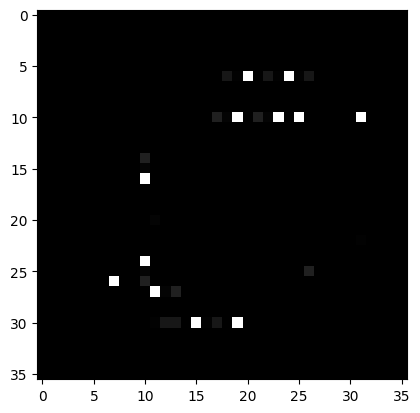

Index: 300


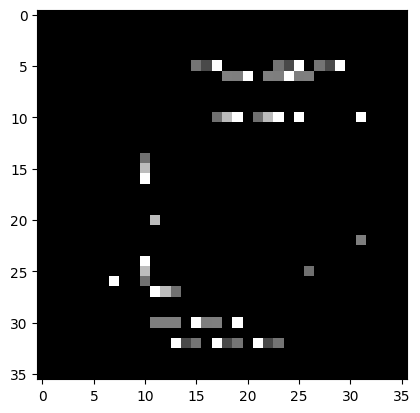

Index: 400


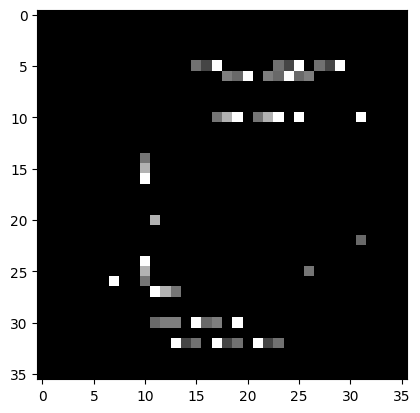

In [4]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler



# Step 4: Generate images and print index and image if index % 40 is 0
image_size = 36  # Example size, adjust as needed
images = [] 
for index, row in df.iterrows():
    image = arrange_in_vortex(row, sorted_indices_desc, image_size)
    images.append(image)
    if index % 100 == 0:
        print(f"Index: {index}")
        plt.imshow(image, cmap='gray')
        plt.show()

images = np.array(images)

# Step 5: Replicate the single-channel images across three channels
images_rgb = np.repeat(images[..., np.newaxis], 3, -1)

# Normalize images
scaler = MinMaxScaler()
images_rgb = scaler.fit_transform(images_rgb.reshape(-1, images_rgb.shape[-1])).reshape(images_rgb.shape)

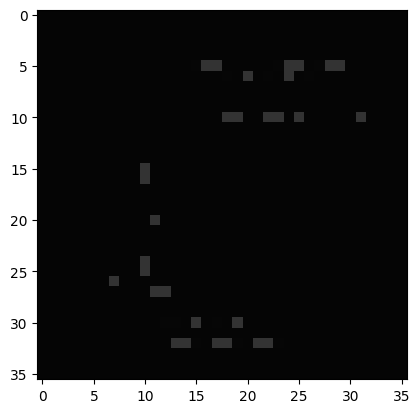

In [5]:

# Example: Show the first image
plt.imshow(images_rgb[0], cmap='gray')
plt.show()

In [6]:
images_rgb[0].shape

(36, 36, 3)

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df2 = pd.read_csv("dataset.csv")

# Change label from 'Suspicious' to 'Critical'
df2["Label"] = df2["Label"].apply(lambda x: "Critical" if x == "Suspicious" else x) 


if os.path.exists('vfp/img') and os.listdir('vfp/img'):
    print("Directory is not empty. Exiting...")
else:
    for index, row in df2.iterrows():
        label = row['Label']
        src_ip = row['src_ip']
        image = images_rgb[index]

        # Create directory if it doesn't exist
        directory = f"vfp/img/{label}"
        if not os.path.exists(directory):
            os.makedirs(directory)
        
        # Save the image using plt.imsave
        file_path = os.path.join(directory, f"{src_ip}.png")
        plt.imsave(file_path, image)

    print("Images saved successfully.")


Directory is not empty. Exiting...


# Run training

## Fitting a CNN Model

In [8]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import torch.nn.functional as F

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        # Reduced pooling size to preserve more information
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.25)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.dropout2 = nn.Dropout(0.25)
        # Additional convolutional layer to capture more complex patterns
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.dropout3 = nn.Dropout(0.25)
        # Batch normalization to stabilize learning
        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)
        self.bn3 = nn.BatchNorm2d(64)
        # Adjusted for an additional pooling layer, resulting in 36/2/2/2 = 4.5 ~ 4 (floor) for the size of feature maps
        self.fc1 = nn.Linear(64 * 4 * 4, 256)  # Adjusted for added complexity and reduced pooling effect
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.dropout1(x)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.dropout2(x)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # Additional pooling layer for the new conv layer
        x = self.dropout3(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor for the fully connected layer
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [10]:
import numpy as np
from sklearn.model_selection import train_test_split

y = df2["Label"]
 
X_train, X_test, y_train, y_test = train_test_split(images_rgb, y, test_size=0.2, random_state=42)

In [11]:
from sklearn.preprocessing import LabelEncoder
from collections import Counter
# from sklearn.model_selection import train_test_split
import numpy as np

#y = df["Label"]
# Add stratify=y to ensure the same distribution of classes in both sets
#X_train, X_test, y_train, y_test = train_test_split(X_REFINED_MDS, y, test_size=0.2, random_state=42, stratify=y)

#y_train = y_train.values
#y_test = y_test.values

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

print(Counter(y_train_enc))
print(Counter(y_test_enc))

Counter({0: 170, 1: 162})
Counter({0: 55, 1: 29})


In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.tensor(X_train[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.tensor(X_test[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_test_tensor = torch.from_numpy(le.transform(y_test))

cuda


In [13]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [14]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-03,
    weight_decay=1e-05
)

In [15]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 0.862
[20] loss: 0.690
[40] loss: 0.652
[60] loss: 0.631
[80] loss: 0.627
[99] loss: 0.626


In [16]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.678
The test accuracy was 0.607


In [17]:
from sklearn.metrics import f1_score, recall_score

# Calculate F1 score
f1 = f1_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

# Calculate Recall
recall = recall_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

print(f"F1 Score: {f1}")
print(f"Recall: {recall}")

F1 Score: 0.6157603686635945
Recall: 0.6071428571428571


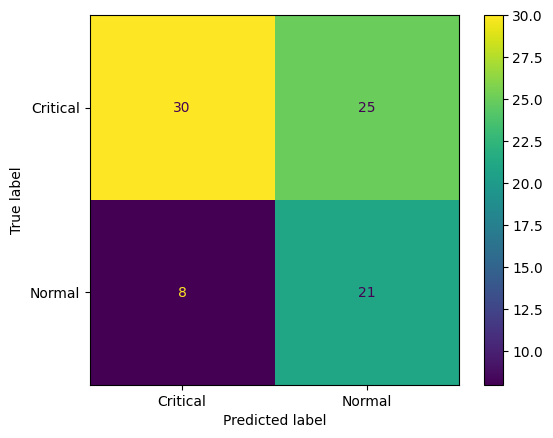

In [18]:
_ = ConfusionMatrixDisplay.from_predictions(y_test_tensor, test_predicted, display_labels=le.classes_)

## Fastai

In [19]:
from fastai.vision.all import *
from sklearn.model_selection import train_test_split

def balanced_splitter(files, valid_pct=0.2, seed=42):
    # Get labels
    labels = [parent_label(f) for f in files]
    
    # Split each class individually and collect train/valid indices
    train_idxs, valid_idxs = [], []
    for cls in set(labels):
        # Indices for current class
        cls_idxs = [i for i, x in enumerate(labels) if x == cls]
        
        # Split indices for the current class
        cls_train_idxs, cls_valid_idxs = train_test_split(cls_idxs, test_size=valid_pct, random_state=seed)
        
        # Append current class indices to the main lists
        train_idxs.extend(cls_train_idxs)
        valid_idxs.extend(cls_valid_idxs)
    
    return train_idxs, valid_idxs

In [20]:
from fastai.vision.all import *

# Step 1: Define the DataBlock
datablock = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(36)  # Resize images to 36x36 if necessary
)

# Step 2: Create a DataLoader
dls = datablock.dataloaders('vfp/img')


## Resnet 18

In [21]:

# Step 3: Load a Pretrained ResNet18 Model
learn = cnn_learner(dls, resnet18, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.213094,0.704759,0.493976,00:01
1,1.143234,0.759496,0.481928,00:00
2,1.042880,0.890986,0.566265,00:00
3,1.004851,1.097846,0.590361,00:00
4,0.939229,1.280138,0.554217,00:00
5,0.900089,0.659284,0.602410,00:00
6,0.882049,0.723794,0.578313,00:00
7,0.856742,0.955058,0.590361,00:00
8,0.840095,1.140759,0.457831,00:00
9,0.817872,1.064662,0.530120,00:00


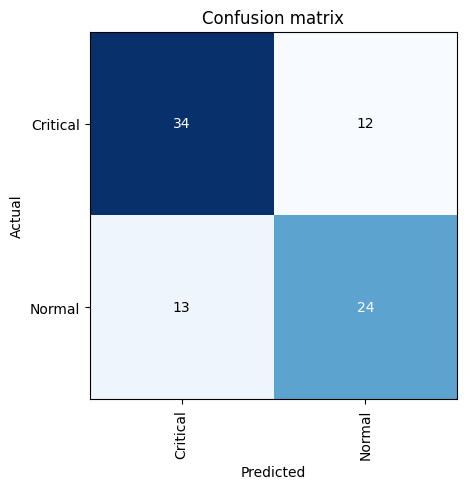

In [22]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet50

In [23]:

# Step 3: Load a   ResNet18 Model
learn = cnn_learner(dls, resnet50, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.340063,0.827329,0.349398,00:01
1,1.258151,0.841012,0.530120,00:00
2,1.160957,0.684706,0.590361,00:00
3,1.113936,1.043326,0.518072,00:01
4,1.100519,1.239140,0.397590,00:00
5,1.092933,1.130872,0.530120,00:00
6,1.057603,1.261985,0.445783,00:00
7,1.037488,1.886169,0.373494,00:00
8,1.036260,13.138086,0.445783,00:00
9,1.009251,36.714336,0.445783,00:00


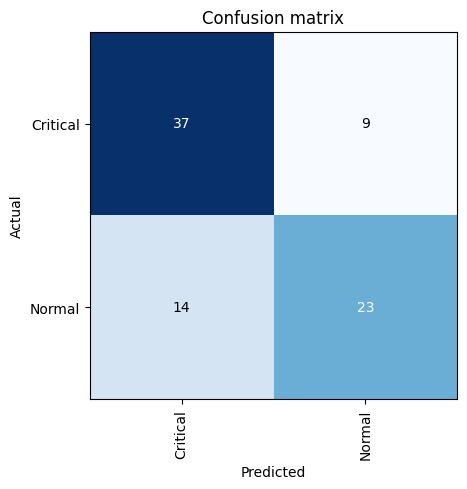

In [24]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

##  Resnet101

In [25]:

# Step 3: Load a Pretrained   Model
learn = cnn_learner(dls, resnet101, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25) 

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.215870,1.115959,0.445783,00:01
1,1.259378,0.617838,0.662651,00:01
2,1.166247,1.026308,0.566265,00:01
3,1.136039,1.163385,0.457831,00:01
4,1.104335,0.870392,0.650602,00:01
5,1.091254,0.816736,0.626506,00:01
6,1.067572,1.293895,0.542169,00:01
7,1.038976,1.588755,0.469880,00:01
8,1.023838,1.120808,0.493976,00:01
9,1.007893,0.974162,0.650602,00:01


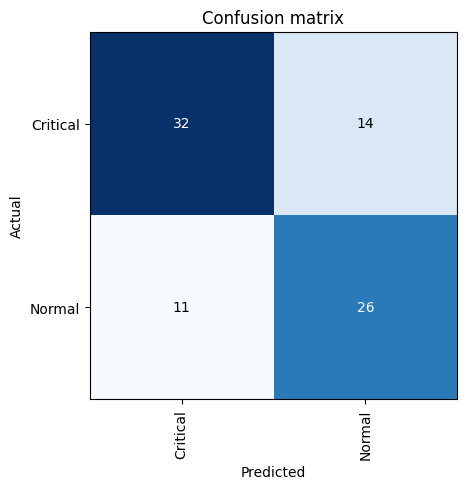

In [26]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet 152

In [27]:
# Step 3: Load a Pretrained   Model
learn = cnn_learner(dls, resnet152, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)


c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.293992,1.519560,0.433735,00:01
1,1.305230,1.108689,0.385542,00:01
2,1.248630,0.993318,0.409639,00:01
3,1.195869,0.787501,0.493976,00:01
4,1.140097,1.491455,0.349398,00:01
5,1.089205,2.730151,0.421687,00:01
6,1.050938,17.834520,0.445783,00:01
7,1.027635,6.705805,0.445783,00:01
8,1.026830,2.807748,0.433735,00:01
9,1.028627,3.347495,0.457831,00:01


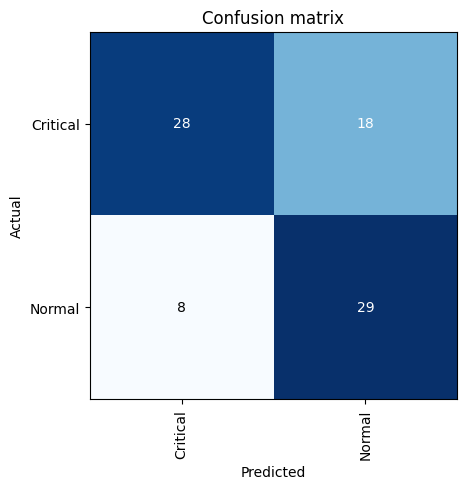

In [28]:

interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()